In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.4,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

SAFE_CLR   = '#2196F3'
ALERT_CLR  = '#FF9800'
RISK_CLR   = '#F44336'
SITE1_CLR  = '#1565C0'
SITE2_CLR  = '#E65100'
RISK_ORDER = ['Safe/Normal (<=260)', 'Elevated/Alert (261-540)', 'High-Risk (>540)']
RISK_COLORS= [SAFE_CLR, ALERT_CLR, RISK_CLR]

THRESH_ALERT = 260
THRESH_RISK  = 540

df = pd.read_excel('Ecoli and LagRainfall.xlsx')
df['DateTime'] = pd.to_datetime(df['DateTime'])
df = df.sort_values('DateTime').reset_index(drop=True)

print(f"Rows: {len(df)}  |  Columns: {df.shape[1]}")
print(f"Date range: {df['DateTime'].min().date()} to {df['DateTime'].max().date()}")
print(f"Sites: {df['Site'].unique().tolist()}")


Rows: 203  |  Columns: 18
Date range: 2021-01-04 to 2026-04-30
Sites: ['Oroua at Almadale', 'Oroua at Almadale Slackline']


In [38]:
display(df.head(8))


,Site,DateTime,Ecoli_MPN_100mL,Log10_Ecoli,Rain_Day0_Calendar_mm,Rain_Lag1d_mm,Rain_Lag2d_mm,Rain_Lag3d_mm,Rain_Lag4d_mm,Rain_Lag5d_mm,Rain_Lag6d_mm,Rain_Lag7d_mm,Rain_Pre6h_mm,Rain_Pre12h_mm,Rain_Pre24h_mm,Rain_Pre48h_mm,Rain_Pre72h_mm,Rain_Pre7d_mm
0,Oroua at Almadale,2021-01-04 08:11:00.000,24200.0,4.383815,26.36,0.00,0.00,0.00,0.00,0.00,4.09,4.09,3.5,5.0,33.5,34.0,34.0,34.0
1,Oroua at Almadale,2021-01-10 12:24:00.000,41.0,1.612784,0.00,6.82,2.73,0.00,0.00,5.46,26.36,0.00,0.0,0.0,0.0,3.0,10.5,44.5
2,Oroua at Almadale,2021-01-18 10:58:00.000,374.0,2.572872,9.55,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.5,4.0,13.5,14.5,14.5,14.5
3,Oroua at Almadale Slackline,2021-01-21 09:00:00.000,1700.0,3.230449,14.55,4.55,6.82,9.55,0.00,0.00,0.00,0.00,0.0,0.0,15.0,21.0,24.5,39.0
4,Oroua at Almadale,2021-01-24 10:44:59.999,63.0,1.799341,0.91,1.82,0.91,14.55,4.55,6.82,9.55,0.00,2.0,7.0,7.0,8.0,11.0,49.0
5,Oroua at Almadale,2021-02-02 08:38:00.000,98.0,1.991226,0.00,0.00,0.00,0.00,1.36,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,1.5
6,Oroua at Almadale,2021-02-07 11:04:00.000,9.0,0.954243,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0
7,Oroua at Almadale,2021-02-15 10:55:00.000,231.0,2.363612,0.00,0.00,0.00,0.00,4.55,0.00,0.00,0.00,0.5,0.5,0.5,0.5,0.5,5.5


In [39]:
summary = pd.DataFrame({
    'dtype':   df.dtypes,
    'non_null': df.notnull().sum(),
    'null':     df.isnull().sum(),
    'null_%':  (df.isnull().mean() * 100).round(1)
})
display(summary)

print()
print("NOTE: Rain_Day0_Calendar_mm and Lag1-Lag7 have 52 nulls.")
print("      These are records from Jan 2025 onward where daily rainfall")
print("      data was not available. Antecedent window columns (Pre6h-Pre7d)")
print("      are complete for all 203 rows and are leakage-safe.")


,dtype,non_null,null,null_%
Site,object,203,0,0.0
DateTime,datetime64[ns],203,0,0.0
Ecoli_MPN_100mL,float64,203,0,0.0
Log10_Ecoli,float64,203,0,0.0
Rain_Day0_Calendar_mm,float64,151,52,25.6
Rain_Lag1d_mm,float64,151,52,25.6
Rain_Lag2d_mm,float64,151,52,25.6
Rain_Lag3d_mm,float64,151,52,25.6
Rain_Lag4d_mm,float64,151,52,25.6
Rain_Lag5d_mm,float64,151,52,25.6



NOTE: Rain_Day0_Calendar_mm and Lag1-Lag7 have 52 nulls.
      These are records from Jan 2025 onward where daily rainfall
      data was not available. Antecedent window columns (Pre6h-Pre7d)
      are complete for all 203 rows and are leakage-safe.


In [40]:
rain_cols = [c for c in df.columns if 'Rain' in c and c != 'Rain_Day0_Calendar_mm']
display(df[['Ecoli_MPN_100mL', 'Log10_Ecoli'] + rain_cols].describe().round(2))


,Ecoli_MPN_100mL,Log10_Ecoli,Rain_Lag1d_mm,Rain_Lag2d_mm,Rain_Lag3d_mm,Rain_Lag4d_mm,Rain_Lag5d_mm,Rain_Lag6d_mm,Rain_Lag7d_mm,Rain_Pre6h_mm,Rain_Pre12h_mm,Rain_Pre24h_mm,Rain_Pre48h_mm,Rain_Pre72h_mm,Rain_Pre7d_mm
count,203.00,203.00,151.00,151.00,151.00,151.00,151.00,151.00,151.00,203.00,203.00,203.00,203.00,203.00,203.00
mean,583.55,2.21,3.70,4.49,3.32,3.80,3.53,3.90,3.35,0.61,1.30,3.54,7.93,12.64,28.35
std,1993.23,0.61,6.77,8.55,5.98,8.10,8.36,9.97,7.65,1.49,2.79,6.65,12.37,17.90,29.35
min,4.00,0.60,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,64.40,1.81,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.50
50%,144.00,2.16,0.45,0.44,0.00,0.40,0.00,0.00,0.00,0.00,0.00,0.00,3.00,6.50,22.50
75%,315.50,2.50,4.42,5.63,3.73,3.24,3.20,4.10,3.68,0.50,1.00,4.75,11.25,17.00,38.00
max,24200.00,4.38,40.74,52.52,26.83,43.60,68.58,99.57,56.50,9.00,16.00,35.00,84.50,138.00,182.00


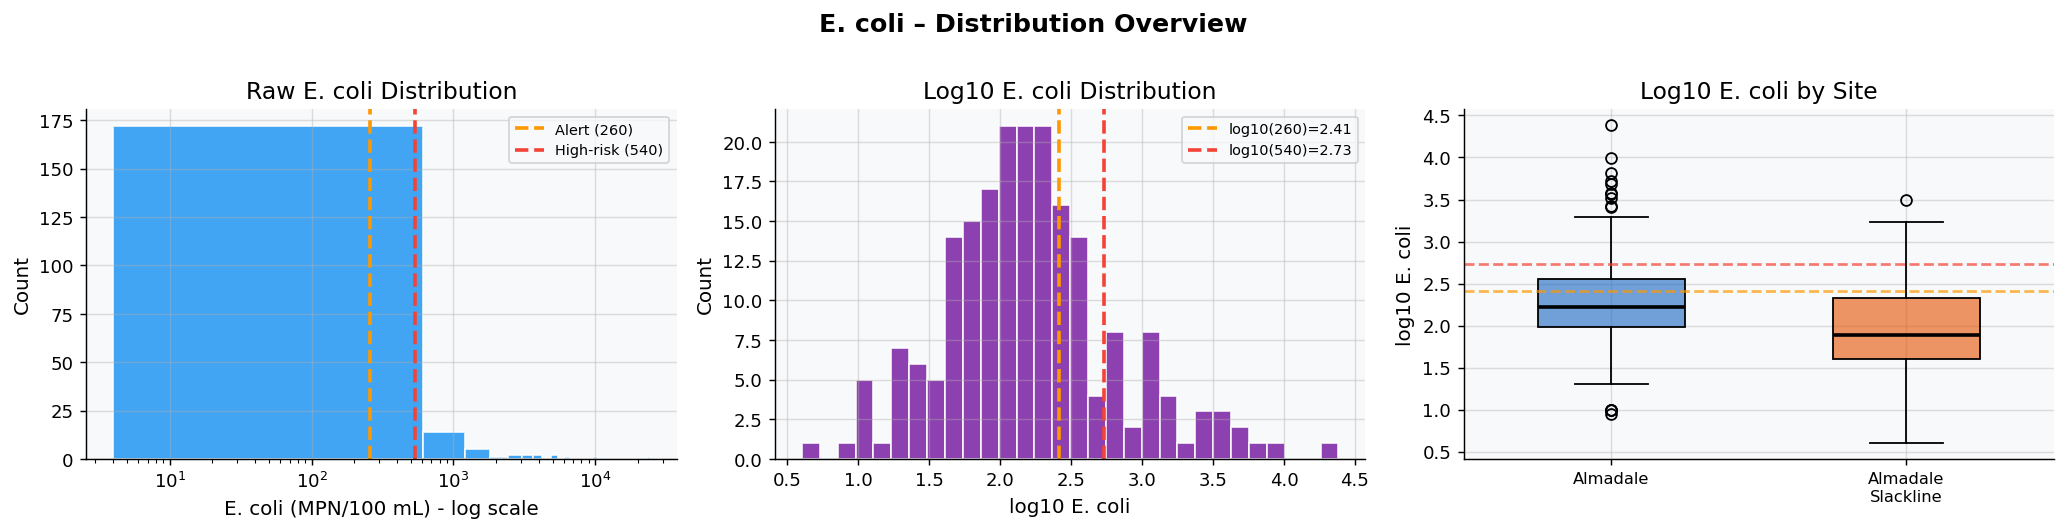

Median E. coli : 144 MPN/100 mL
Mean   E. coli : 584 MPN/100 mL  (skewed by extremes)
Max    E. coli : 24200 MPN/100 mL
Geometric mean : 161 MPN/100 mL


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.hist(df['Ecoli_MPN_100mL'], bins=40, color=SAFE_CLR, edgecolor='white', alpha=0.85)
ax.axvline(THRESH_ALERT, color=ALERT_CLR, lw=2, ls='--', label=f'Alert ({THRESH_ALERT})')
ax.axvline(THRESH_RISK,  color=RISK_CLR,  lw=2, ls='--', label=f'High-risk ({THRESH_RISK})')
ax.set_xscale('log')
ax.set_xlabel('E. coli (MPN/100 mL) - log scale')
ax.set_ylabel('Count')
ax.set_title('Raw E. coli Distribution')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(df['Log10_Ecoli'], bins=30, color='#7B1FA2', edgecolor='white', alpha=0.85)
ax.axvline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=2, ls='--',
           label=f'log10({THRESH_ALERT})={np.log10(THRESH_ALERT):.2f}')
ax.axvline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=2, ls='--',
           label=f'log10({THRESH_RISK})={np.log10(THRESH_RISK):.2f}')
ax.set_xlabel('log10 E. coli')
ax.set_ylabel('Count')
ax.set_title('Log10 E. coli Distribution')
ax.legend(fontsize=8)

ax = axes[2]
site_data = [df.loc[df['Site'] == s, 'Log10_Ecoli'].values for s in df['Site'].unique()]
bp = ax.boxplot(site_data, patch_artist=True, widths=0.5,
                medianprops=dict(color='black', lw=2))
bp['boxes'][0].set_facecolor(SITE1_CLR + '99')
bp['boxes'][1].set_facecolor(SITE2_CLR + '99')
ax.set_xticklabels(['Almadale', 'Almadale\nSlackline'], fontsize=9)
ax.set_ylabel('log10 E. coli')
ax.set_title('Log10 E. coli by Site')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--', alpha=0.7)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--', alpha=0.7)

plt.suptitle('E. coli – Distribution Overview', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig01_ecoli_distribution.png', bbox_inches='tight')
plt.show()

print(f"Median E. coli : {df['Ecoli_MPN_100mL'].median():.0f} MPN/100 mL")
print(f"Mean   E. coli : {df['Ecoli_MPN_100mL'].mean():.0f} MPN/100 mL  (skewed by extremes)")
print(f"Max    E. coli : {df['Ecoli_MPN_100mL'].max():.0f} MPN/100 mL")
print(f"Geometric mean : {10**df['Log10_Ecoli'].mean():.0f} MPN/100 mL")


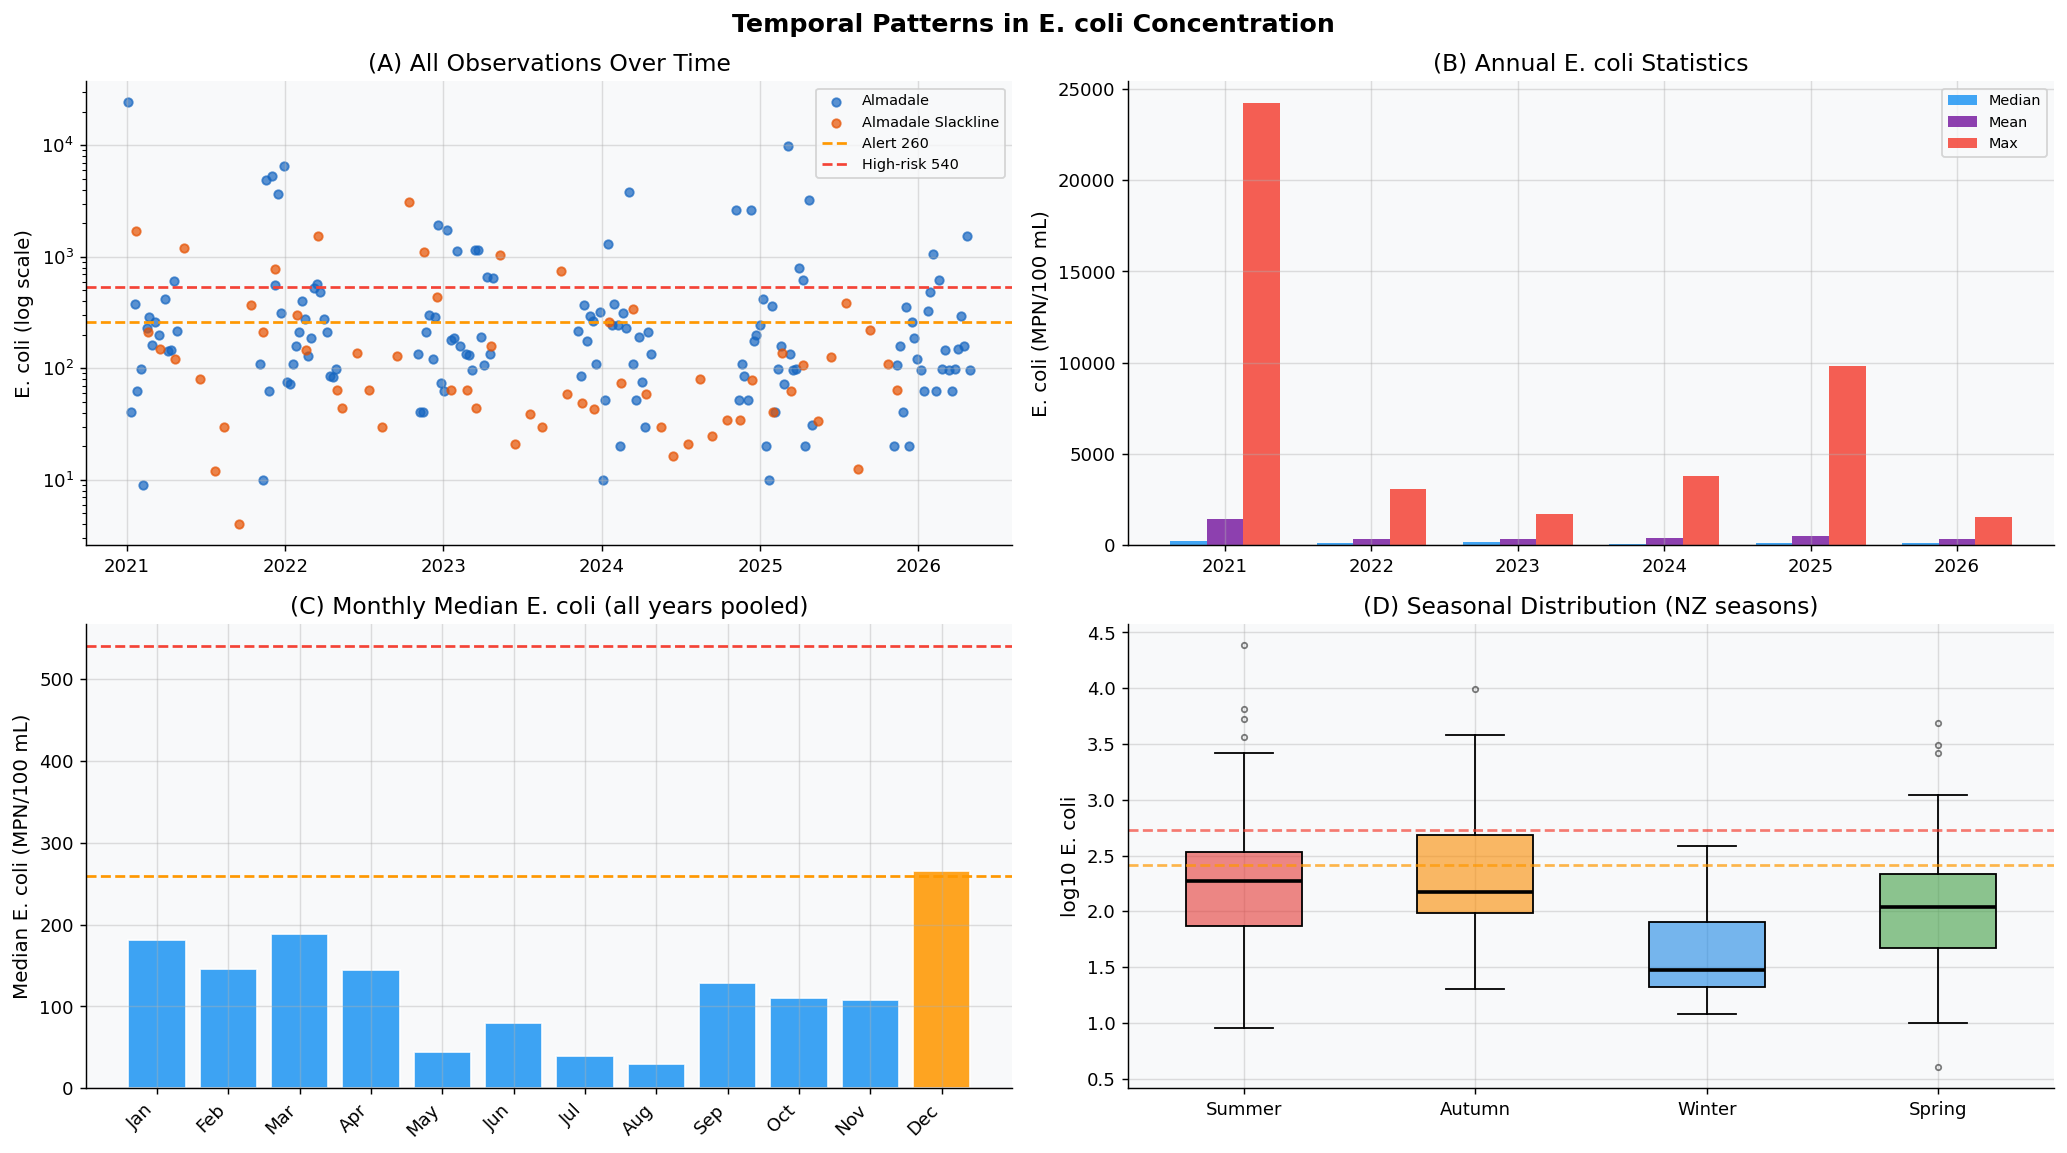

In [42]:
df['Year']     = df['DateTime'].dt.year
df['Month']    = df['DateTime'].dt.month
df['Month_nm'] = df['DateTime'].dt.strftime('%b')
df['Season']   = df['Month'].map({
    12:'Summer', 1:'Summer', 2:'Summer',
    3:'Autumn',  4:'Autumn', 5:'Autumn',
    6:'Winter',  7:'Winter', 8:'Winter',
    9:'Spring', 10:'Spring', 11:'Spring'
})

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

ax = axes[0, 0]
for site, clr in zip(df['Site'].unique(), [SITE1_CLR, SITE2_CLR]):
    sub = df[df['Site'] == site]
    ax.scatter(sub['DateTime'], sub['Ecoli_MPN_100mL'],
               color=clr, s=22, alpha=0.7, label=site.replace('Oroua at ', ''))
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--', label='Alert 260')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--', label='High-risk 540')
ax.set_yscale('log')
ax.set_ylabel('E. coli (log scale)')
ax.set_title('(A) All Observations Over Time')
ax.legend(fontsize=8)

ax = axes[0, 1]
annual = df.groupby('Year')['Ecoli_MPN_100mL'].agg(['median','mean','max']).reset_index()
w = 0.25
x = np.arange(len(annual))
ax.bar(x-w, annual['median'], width=w, label='Median', color=SAFE_CLR, alpha=0.85)
ax.bar(x,   annual['mean'],   width=w, label='Mean',   color='#7B1FA2', alpha=0.85)
ax.bar(x+w, annual['max'],    width=w, label='Max',    color=RISK_CLR,  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(annual['Year'])
ax.set_ylabel('E. coli (MPN/100 mL)')
ax.set_title('(B) Annual E. coli Statistics')
ax.legend(fontsize=8)

ax = axes[1, 0]
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = df.groupby('Month_nm')['Ecoli_MPN_100mL'].median().reindex(month_order)
colors_m = [RISK_CLR if v > THRESH_RISK else (ALERT_CLR if v > THRESH_ALERT else SAFE_CLR)
            for v in monthly]
ax.bar(range(12), monthly.values, color=colors_m, edgecolor='white', alpha=0.87)
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
ax.set_ylabel('Median E. coli (MPN/100 mL)')
ax.set_title('(C) Monthly Median E. coli (all years pooled)')

ax = axes[1, 1]
season_order  = ['Summer','Autumn','Winter','Spring']
season_colors = ['#E53935','#FB8C00','#1E88E5','#43A047']
for i, (seas, clr) in enumerate(zip(season_order, season_colors)):
    sub = df[df['Season'] == seas]['Log10_Ecoli']
    bp = ax.boxplot(sub, positions=[i], patch_artist=True, widths=0.5,
                    medianprops=dict(color='black', lw=2),
                    flierprops=dict(marker='o', markersize=3, alpha=0.5))
    bp['boxes'][0].set_facecolor(clr + '99')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--', alpha=0.7)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--', alpha=0.7)
ax.set_xticks(range(4))
ax.set_xticklabels(season_order)
ax.set_ylabel('log10 E. coli')
ax.set_title('(D) Seasonal Distribution (NZ seasons)')

plt.suptitle('Temporal Patterns in E. coli Concentration', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig02_temporal.png', bbox_inches='tight')
plt.show()


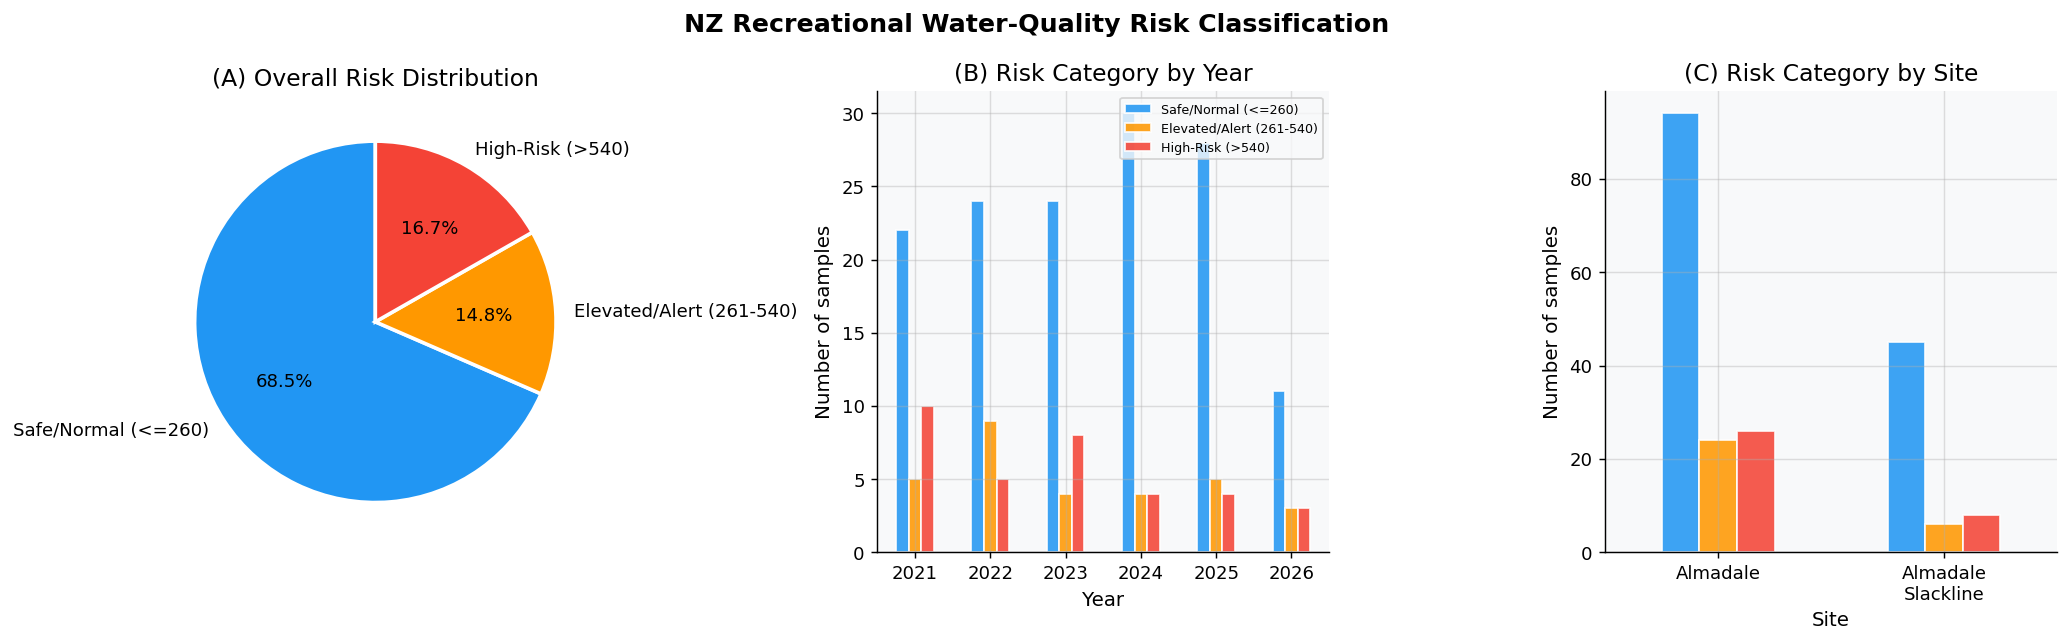

Risk category summary:
                          Count  Percentage (%)
Risk_Label                                     
Safe/Normal (<=260)         139            68.5
Elevated/Alert (261-540)     30            14.8
High-Risk (>540)             34            16.7


In [43]:
def classify_risk(val):
    if val <= THRESH_ALERT:   return 'Safe/Normal (<=260)'
    elif val <= THRESH_RISK:  return 'Elevated/Alert (261-540)'
    else:                     return 'High-Risk (>540)'

df['Risk_Label'] = df['Ecoli_MPN_100mL'].apply(classify_risk)
risk_counts = df['Risk_Label'].value_counts().reindex(RISK_ORDER)
pct = (risk_counts / len(df) * 100).round(1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
wedges, texts, autotexts = ax.pie(
    risk_counts, labels=RISK_ORDER, colors=RISK_COLORS,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2))
for at in autotexts: at.set_fontsize(10)
ax.set_title('(A) Overall Risk Distribution')

ax = axes[1]
yr_risk = df.groupby(['Year','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
yr_risk.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87, legend=False)
ax.set_xticklabels(yr_risk.index, rotation=0)
ax.set_ylabel('Number of samples')
ax.set_title('(B) Risk Category by Year')
ax.legend(RISK_ORDER, fontsize=7, loc='upper right')

ax = axes[2]
site_risk = df.groupby(['Site','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
site_risk.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87, legend=False)
ax.set_xticklabels(['Almadale','Almadale\nSlackline'], rotation=0)
ax.set_ylabel('Number of samples')
ax.set_title('(C) Risk Category by Site')

plt.suptitle('NZ Recreational Water-Quality Risk Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig03_risk_classification.png', bbox_inches='tight')
plt.show()

print("Risk category summary:")
print(pd.DataFrame({'Count': risk_counts, 'Percentage (%)': pct}).to_string())


Rows used for daily lag analysis: 151  (post-2025 NaN rows excluded)


,Lag,Pearson_r,p_value,CI_lower,CI_upper,Significant
0,Lag 1d,0.2112,0.0092,0.0533,0.3588,True
1,Lag 2d,0.1666,0.0409,0.0071,0.3179,True
2,Lag 3d,0.0266,0.7458,-0.1337,0.1855,False
3,Lag 4d,0.0688,0.4010,-0.0919,0.2261,False
4,Lag 5d,-0.0057,0.9446,-0.1653,0.1542,False
5,Lag 6d,-0.0648,0.4290,-0.2223,0.0959,False
6,Lag 7d,-0.0437,0.5939,-0.2020,0.1168,False


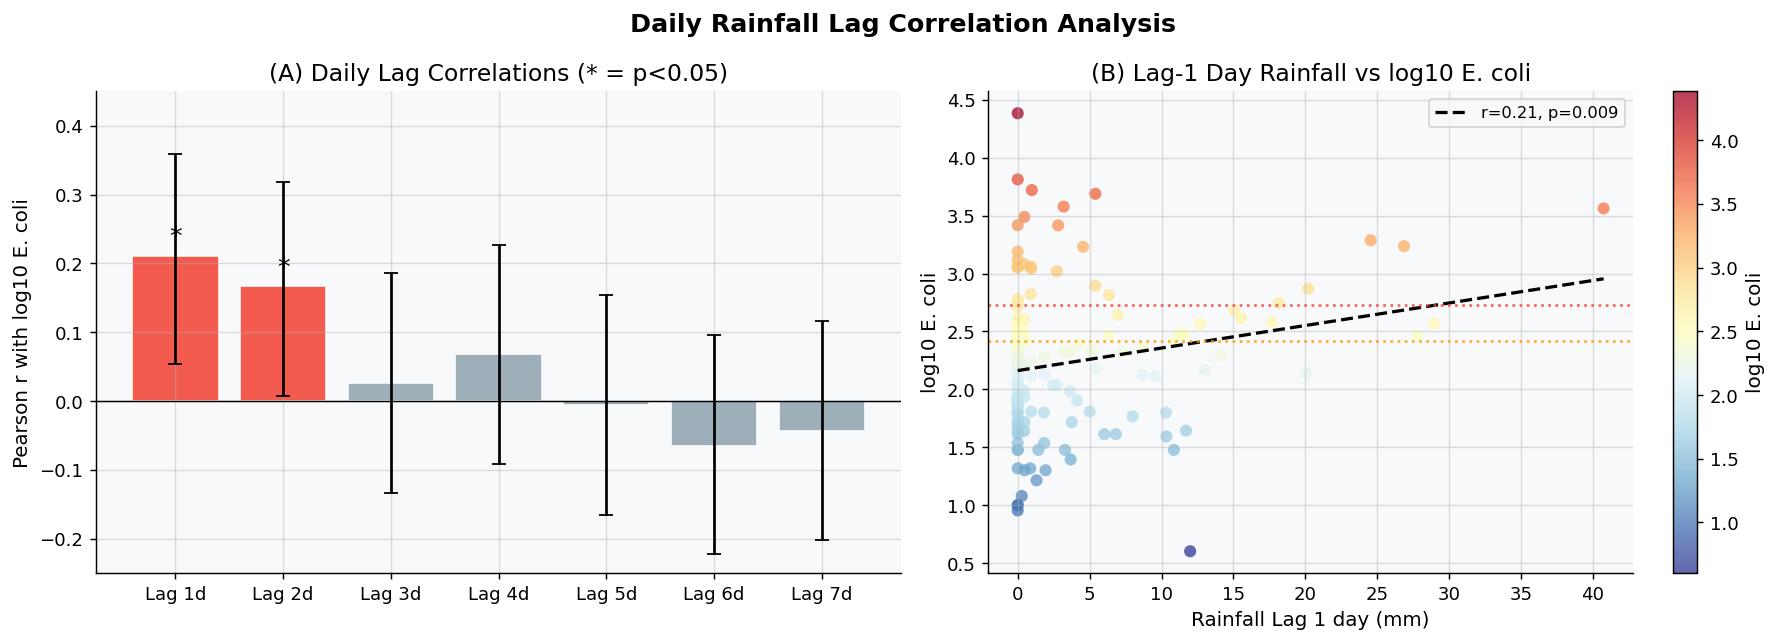

In [44]:
lag_cols   = [f'Rain_Lag{i}d_mm' for i in range(1, 8)]
lag_labels = [f'Lag {i}d' for i in range(1, 8)]

df_lag = df[lag_cols + ['Log10_Ecoli']].dropna()
print(f"Rows used for daily lag analysis: {len(df_lag)}  (post-2025 NaN rows excluded)")

pearson_r, pearson_p, ci_lo, ci_hi = [], [], [], []
for col in lag_cols:
    r, p = stats.pearsonr(df_lag[col], df_lag['Log10_Ecoli'])
    n = len(df_lag)
    z  = np.arctanh(r); se = 1/np.sqrt(n-3)
    pearson_r.append(r); pearson_p.append(p)
    ci_lo.append(np.tanh(z - 1.96*se))
    ci_hi.append(np.tanh(z + 1.96*se))

corr_df = pd.DataFrame({
    'Lag': lag_labels, 'Pearson_r': pearson_r, 'p_value': pearson_p,
    'CI_lower': ci_lo, 'CI_upper': ci_hi,
    'Significant': [p < 0.05 for p in pearson_p]
})
display(corr_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors_lag = [RISK_CLR if sig else '#90A4AE' for sig in corr_df['Significant']]
bars = ax.bar(lag_labels, corr_df['Pearson_r'], color=colors_lag, edgecolor='white', alpha=0.87)
err_lo = corr_df['Pearson_r'] - corr_df['CI_lower']
err_hi = corr_df['CI_upper']  - corr_df['Pearson_r']
ax.errorbar(lag_labels, corr_df['Pearson_r'],
            yerr=[err_lo, err_hi], fmt='none', color='black', capsize=4, lw=1.5)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Pearson r with log10 E. coli')
ax.set_title('(A) Daily Lag Correlations (* = p<0.05)')
ax.set_ylim(-0.25, 0.45)
for bar, sig in zip(bars, corr_df['Significant']):
    if sig:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01, '*', ha='center', va='bottom', fontsize=14)

ax = axes[1]
sub = df_lag.dropna(subset=['Rain_Lag1d_mm'])
sc = ax.scatter(sub['Rain_Lag1d_mm'], sub['Log10_Ecoli'],
                c=sub['Log10_Ecoli'], cmap='RdYlBu_r', s=45, alpha=0.75, edgecolors='none')
m, b, r, p, _ = stats.linregress(sub['Rain_Lag1d_mm'], sub['Log10_Ecoli'])
x_rng = np.linspace(sub['Rain_Lag1d_mm'].min(), sub['Rain_Lag1d_mm'].max(), 100)
ax.plot(x_rng, m*x_rng + b, 'k--', lw=1.8, label=f'r={r:.2f}, p={p:.3f}')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls=':', alpha=0.8)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls=':', alpha=0.8)
ax.set_xlabel('Rainfall Lag 1 day (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(B) Lag-1 Day Rainfall vs log10 E. coli')
ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='log10 E. coli')

plt.suptitle('Daily Rainfall Lag Correlation Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig04_daily_lag_correlation.png', bbox_inches='tight')
plt.show()


,Window,Pearson_r,p_value,CI_lower,CI_upper,Significant
0,6 h,0.2458,0.0004,0.1119,0.3710,True
1,12 h,0.2991,0.0000,0.1683,0.4196,True
2,24 h,0.5915,0.0000,0.4941,0.6743,True
3,48 h,0.5843,0.0000,0.4857,0.6683,True
4,72 h,0.4793,0.0000,0.3657,0.5788,True
5,7 d,0.3057,0.0000,0.1754,0.4255,True


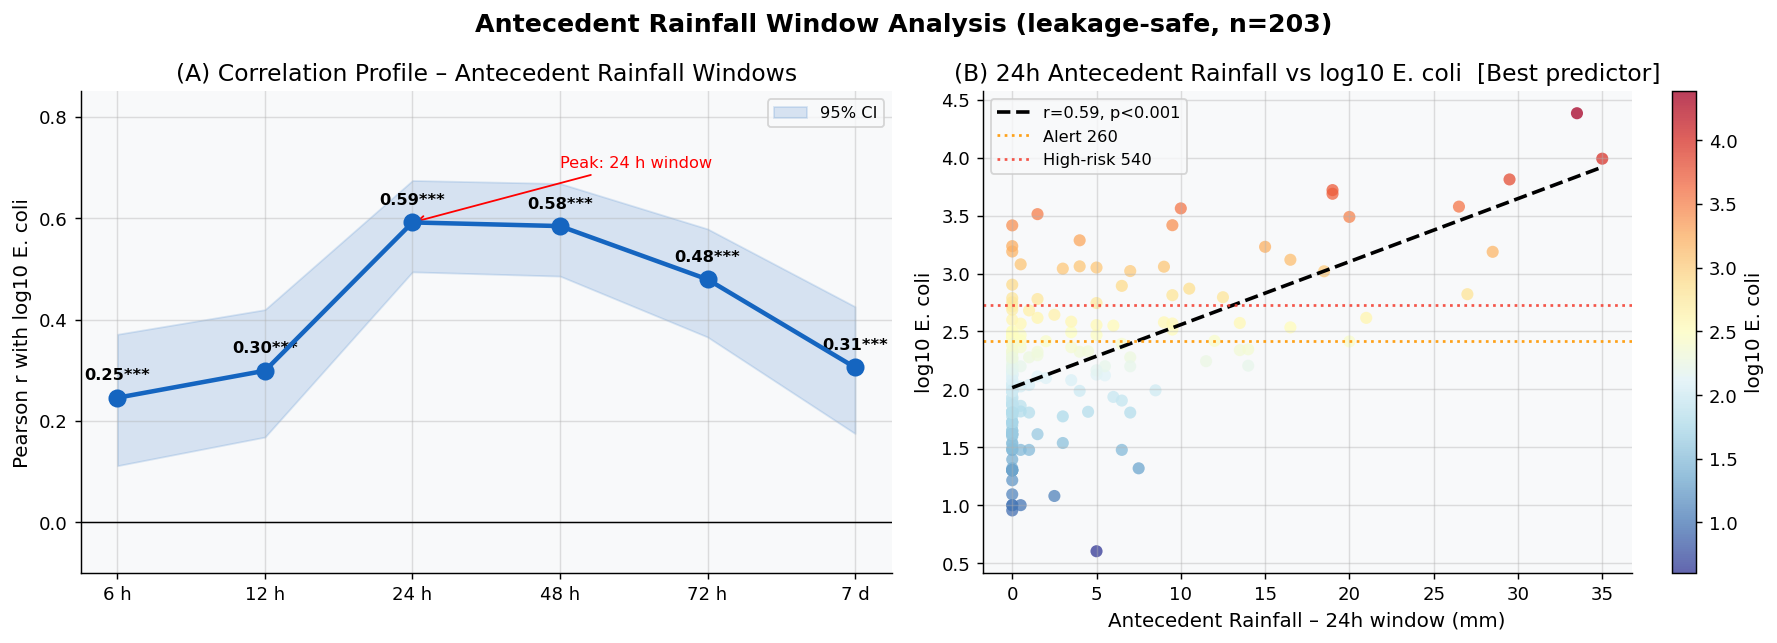

In [45]:
ante_cols   = ['Rain_Pre6h_mm','Rain_Pre12h_mm','Rain_Pre24h_mm',
               'Rain_Pre48h_mm','Rain_Pre72h_mm','Rain_Pre7d_mm']
ante_labels = ['6 h','12 h','24 h','48 h','72 h','7 d']

ante_r, ante_p, ante_lo, ante_hi = [], [], [], []
for col in ante_cols:
    r, p = stats.pearsonr(df[col], df['Log10_Ecoli'])
    n = len(df); z = np.arctanh(r); se = 1/np.sqrt(n-3)
    ante_r.append(r); ante_p.append(p)
    ante_lo.append(np.tanh(z - 1.96*se))
    ante_hi.append(np.tanh(z + 1.96*se))

ante_df = pd.DataFrame({
    'Window': ante_labels, 'Pearson_r': ante_r, 'p_value': ante_p,
    'CI_lower': ante_lo, 'CI_upper': ante_hi,
    'Significant': [p < 0.05 for p in ante_p]
})
display(ante_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(ante_labels, ante_df['Pearson_r'], 'o-', color='#1565C0', lw=2.5, ms=9, zorder=5)
ax.fill_between(ante_labels, ante_df['CI_lower'], ante_df['CI_upper'],
                alpha=0.15, color='#1565C0', label='95% CI')
ax.axhline(0, color='black', lw=0.8)
for i, (lab, r, p) in enumerate(zip(ante_labels, ante_df['Pearson_r'], ante_df['p_value'])):
    star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    ax.annotate(f'{r:.2f}{star}', (lab, r), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Pearson r with log10 E. coli')
ax.set_title('(A) Correlation Profile – Antecedent Rainfall Windows')
ax.legend(fontsize=9)
ax.set_ylim(-0.1, 0.85)
best_idx = np.argmax(ante_df['Pearson_r'])
ax.annotate(f'Peak: {ante_labels[best_idx]} window',
            xy=(ante_labels[best_idx], ante_df['Pearson_r'].iloc[best_idx]),
            xytext=(ante_labels[best_idx+1], 0.70),
            arrowprops=dict(arrowstyle='->', color='red'),
            fontsize=9, color='red')

ax = axes[1]
sc = ax.scatter(df['Rain_Pre24h_mm'], df['Log10_Ecoli'],
                c=df['Log10_Ecoli'], cmap='RdYlBu_r', s=45, alpha=0.75, edgecolors='none')
m, b, r, p, _ = stats.linregress(df['Rain_Pre24h_mm'], df['Log10_Ecoli'])
x_rng = np.linspace(0, df['Rain_Pre24h_mm'].max(), 200)
ax.plot(x_rng, m*x_rng + b, 'k--', lw=2, label=f'r={r:.2f}, p<0.001')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls=':', alpha=0.9, label='Alert 260')
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls=':', alpha=0.9, label='High-risk 540')
ax.set_xlabel('Antecedent Rainfall – 24h window (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(B) 24h Antecedent Rainfall vs log10 E. coli  [Best predictor]')
ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='log10 E. coli')

plt.suptitle('Antecedent Rainfall Window Analysis (leakage-safe, n=203)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig05_antecedent_windows.png', bbox_inches='tight')
plt.show()


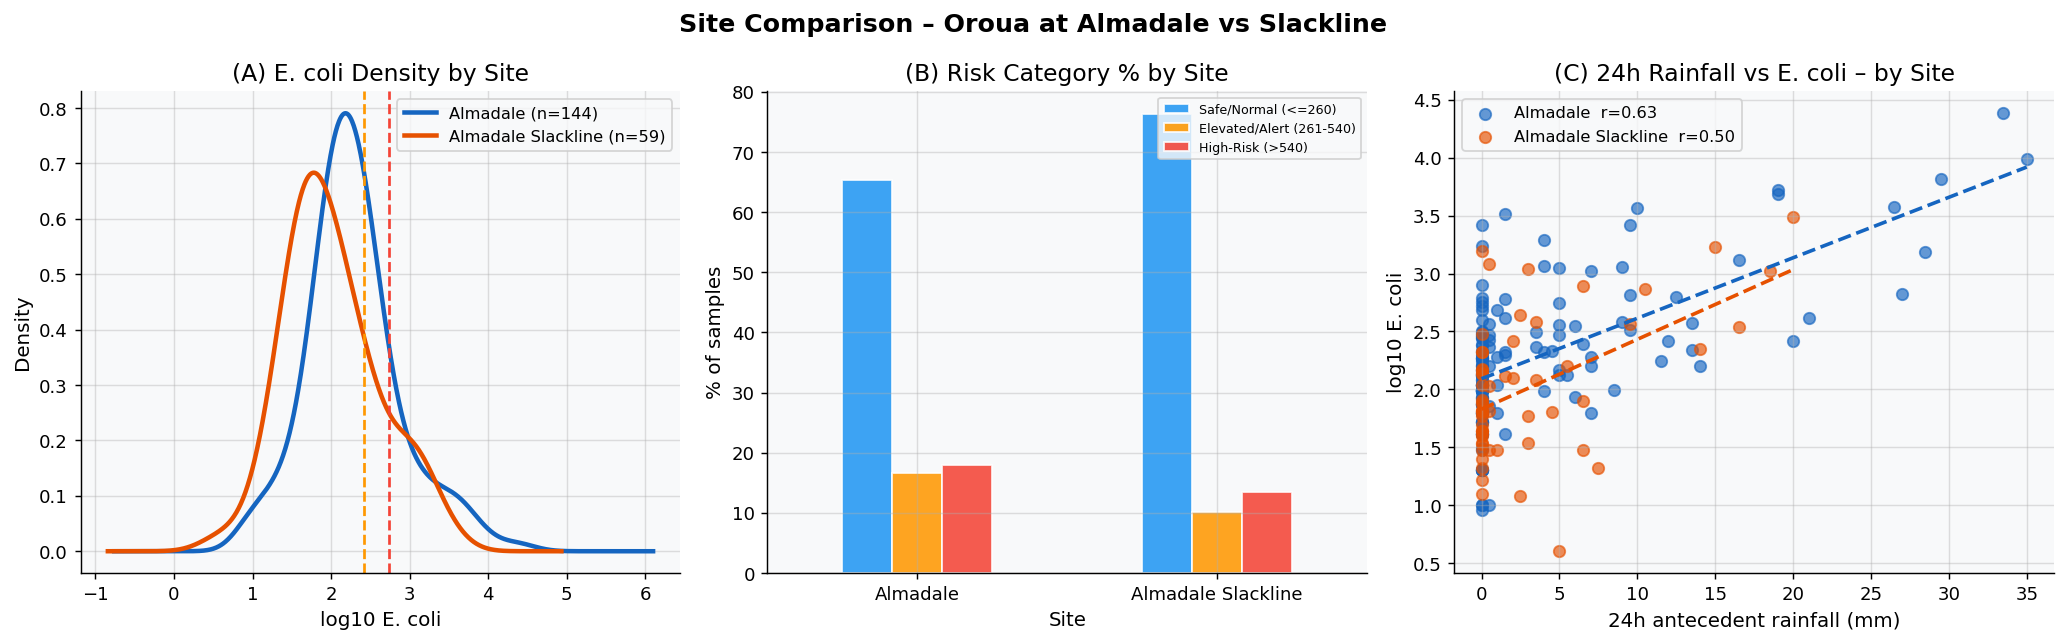

Mann-Whitney U test: U=5479, p=0.0012
  Sites ARE statistically different (p<0.05)


In [46]:
sites = df['Site'].unique()
site_labels = ['Almadale', 'Almadale Slackline']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
for site, clr, lbl in zip(sites, [SITE1_CLR, SITE2_CLR], site_labels):
    sub = df[df['Site'] == site]['Log10_Ecoli']
    sub.plot.kde(ax=ax, color=clr, lw=2.5, label=f'{lbl} (n={len(sub)})')
ax.axvline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--')
ax.axvline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_xlabel('log10 E. coli')
ax.set_title('(A) E. coli Density by Site')
ax.legend(fontsize=9)

ax = axes[1]
site_risk = df.groupby(['Site','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
site_risk_pct = site_risk.div(site_risk.sum(axis=1), axis=0) * 100
site_risk_pct.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87)
ax.set_xticklabels(site_labels, rotation=0)
ax.set_ylabel('% of samples')
ax.set_title('(B) Risk Category % by Site')
ax.legend(RISK_ORDER, fontsize=7, loc='upper right')

ax = axes[2]
for site, clr, lbl in zip(sites, [SITE1_CLR, SITE2_CLR], site_labels):
    sub = df[df['Site'] == site]
    r, p = stats.pearsonr(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'])
    ax.scatter(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'],
               color=clr, alpha=0.65, s=40, label=f'{lbl}  r={r:.2f}')
    m, b, *_ = stats.linregress(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'])
    x_r = np.linspace(0, sub['Rain_Pre24h_mm'].max(), 100)
    ax.plot(x_r, m*x_r + b, color=clr, lw=2, ls='--')
ax.set_xlabel('24h antecedent rainfall (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(C) 24h Rainfall vs E. coli – by Site')
ax.legend(fontsize=9)

plt.suptitle('Site Comparison – Oroua at Almadale vs Slackline',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig06_site_comparison.png', bbox_inches='tight')
plt.show()

g1 = df[df['Site'] == sites[0]]['Log10_Ecoli']
g2 = df[df['Site'] == sites[1]]['Log10_Ecoli']
stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
print(f"Mann-Whitney U test: U={stat:.0f}, p={p:.4f}")
if p > 0.05:
    print("  Sites are NOT statistically different (p>0.05) -> pooling defensible")
else:
    print("  Sites ARE statistically different (p<0.05)")


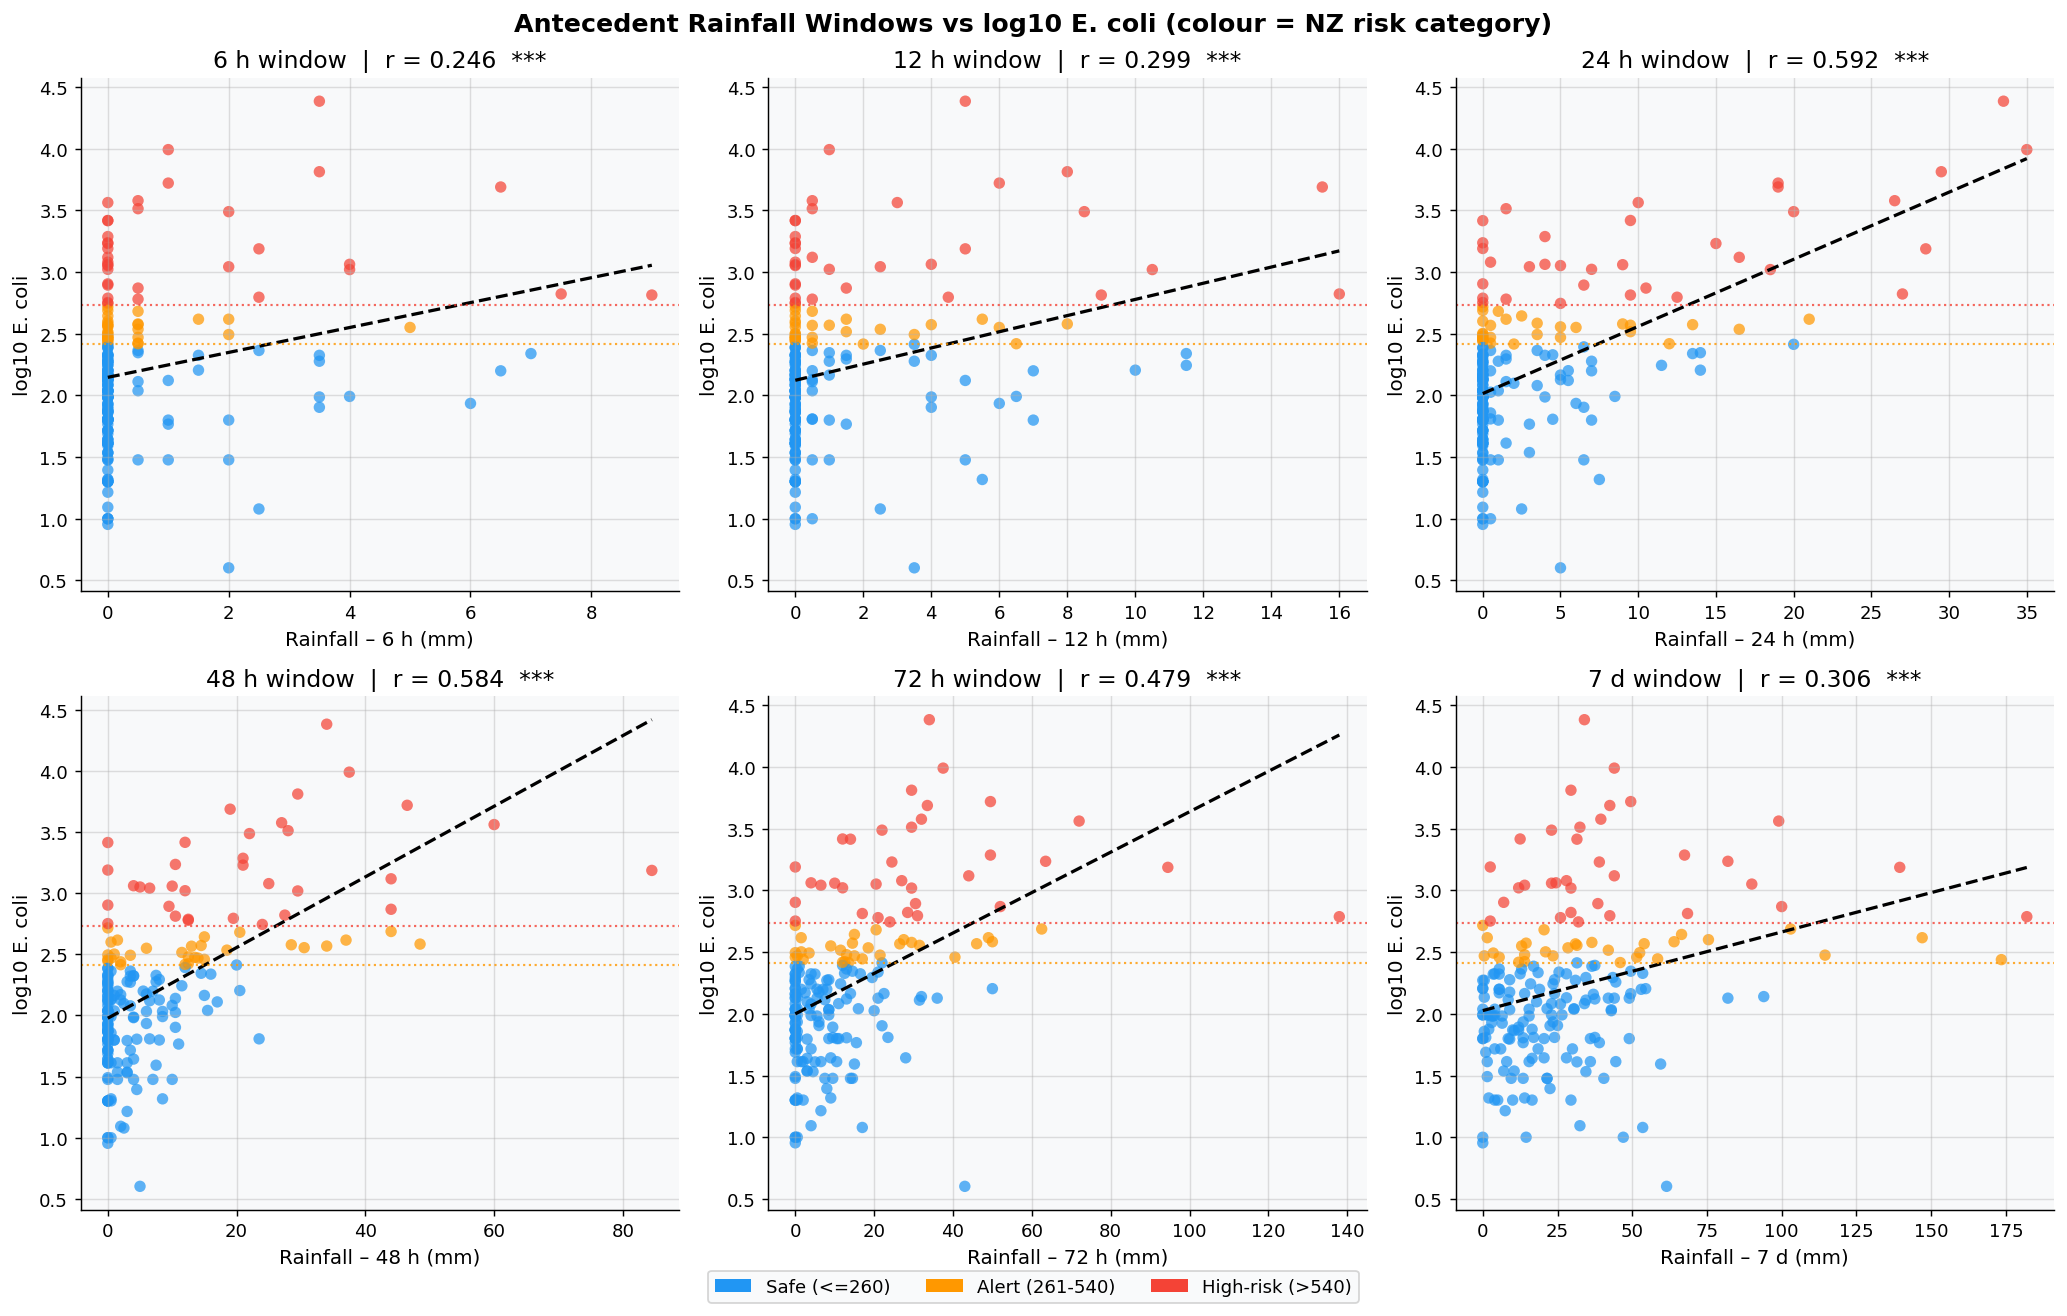

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

clr_map2 = {'Safe/Normal (<=260)': SAFE_CLR,
             'Elevated/Alert (261-540)': ALERT_CLR,
             'High-Risk (>540)': RISK_CLR}

for ax, col, lbl in zip(axes, ante_cols, ante_labels):
    r, p = stats.pearsonr(df[col], df['Log10_Ecoli'])
    pt_colors = [clr_map2[v] for v in df['Risk_Label']]
    ax.scatter(df[col], df['Log10_Ecoli'], c=pt_colors, s=40, alpha=0.72, edgecolors='none')
    m, b, *_ = stats.linregress(df[col], df['Log10_Ecoli'])
    x_r = np.linspace(0, df[col].max(), 200)
    ax.plot(x_r, m*x_r + b, 'k--', lw=1.8)
    ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.2, ls=':', alpha=0.8)
    ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.2, ls=':', alpha=0.8)
    ax.set_xlabel(f'Rainfall – {lbl} (mm)')
    ax.set_ylabel('log10 E. coli')
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    ax.set_title(f'{lbl} window  |  r = {r:.3f}  {sig}')

from matplotlib.patches import Patch
legend_els = [Patch(facecolor=SAFE_CLR,  label='Safe (<=260)'),
              Patch(facecolor=ALERT_CLR, label='Alert (261-540)'),
              Patch(facecolor=RISK_CLR,  label='High-risk (>540)')]
fig.legend(handles=legend_els, loc='lower center', ncol=3, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.suptitle('Antecedent Rainfall Windows vs log10 E. coli (colour = NZ risk category)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig07_scatter_all_windows.png', bbox_inches='tight')
plt.show()


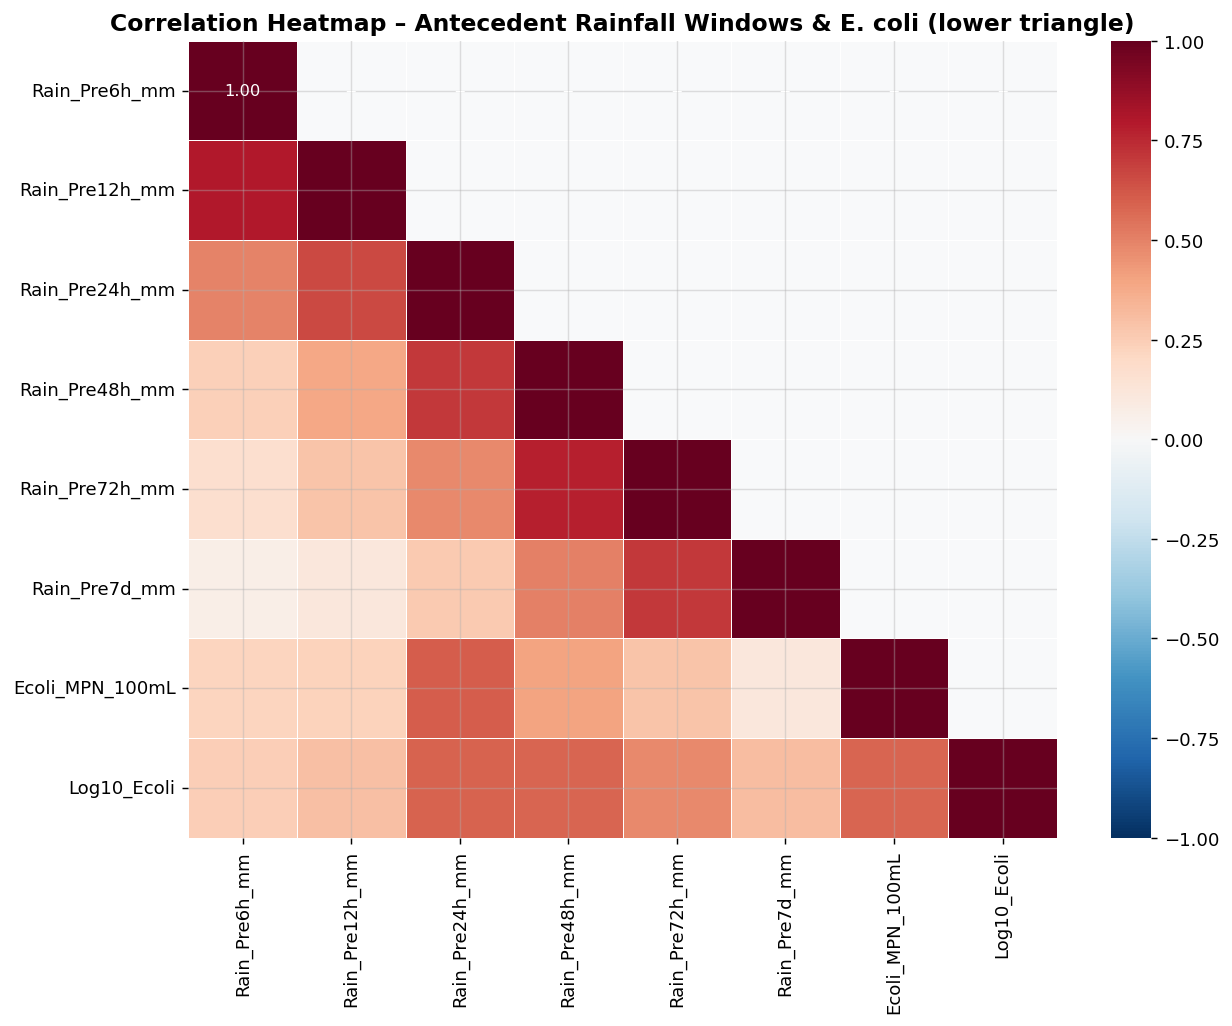

In [48]:
all_model_cols = ante_cols + ['Ecoli_MPN_100mL', 'Log10_Ecoli']
corr_matrix = df[all_model_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, mask=mask,
            linewidths=0.5, linecolor='white', annot_kws={'size': 9})
ax.set_title('Correlation Heatmap – Antecedent Rainfall Windows & E. coli (lower triangle)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig08_correlation_heatmap.png', bbox_inches='tight')
plt.show()


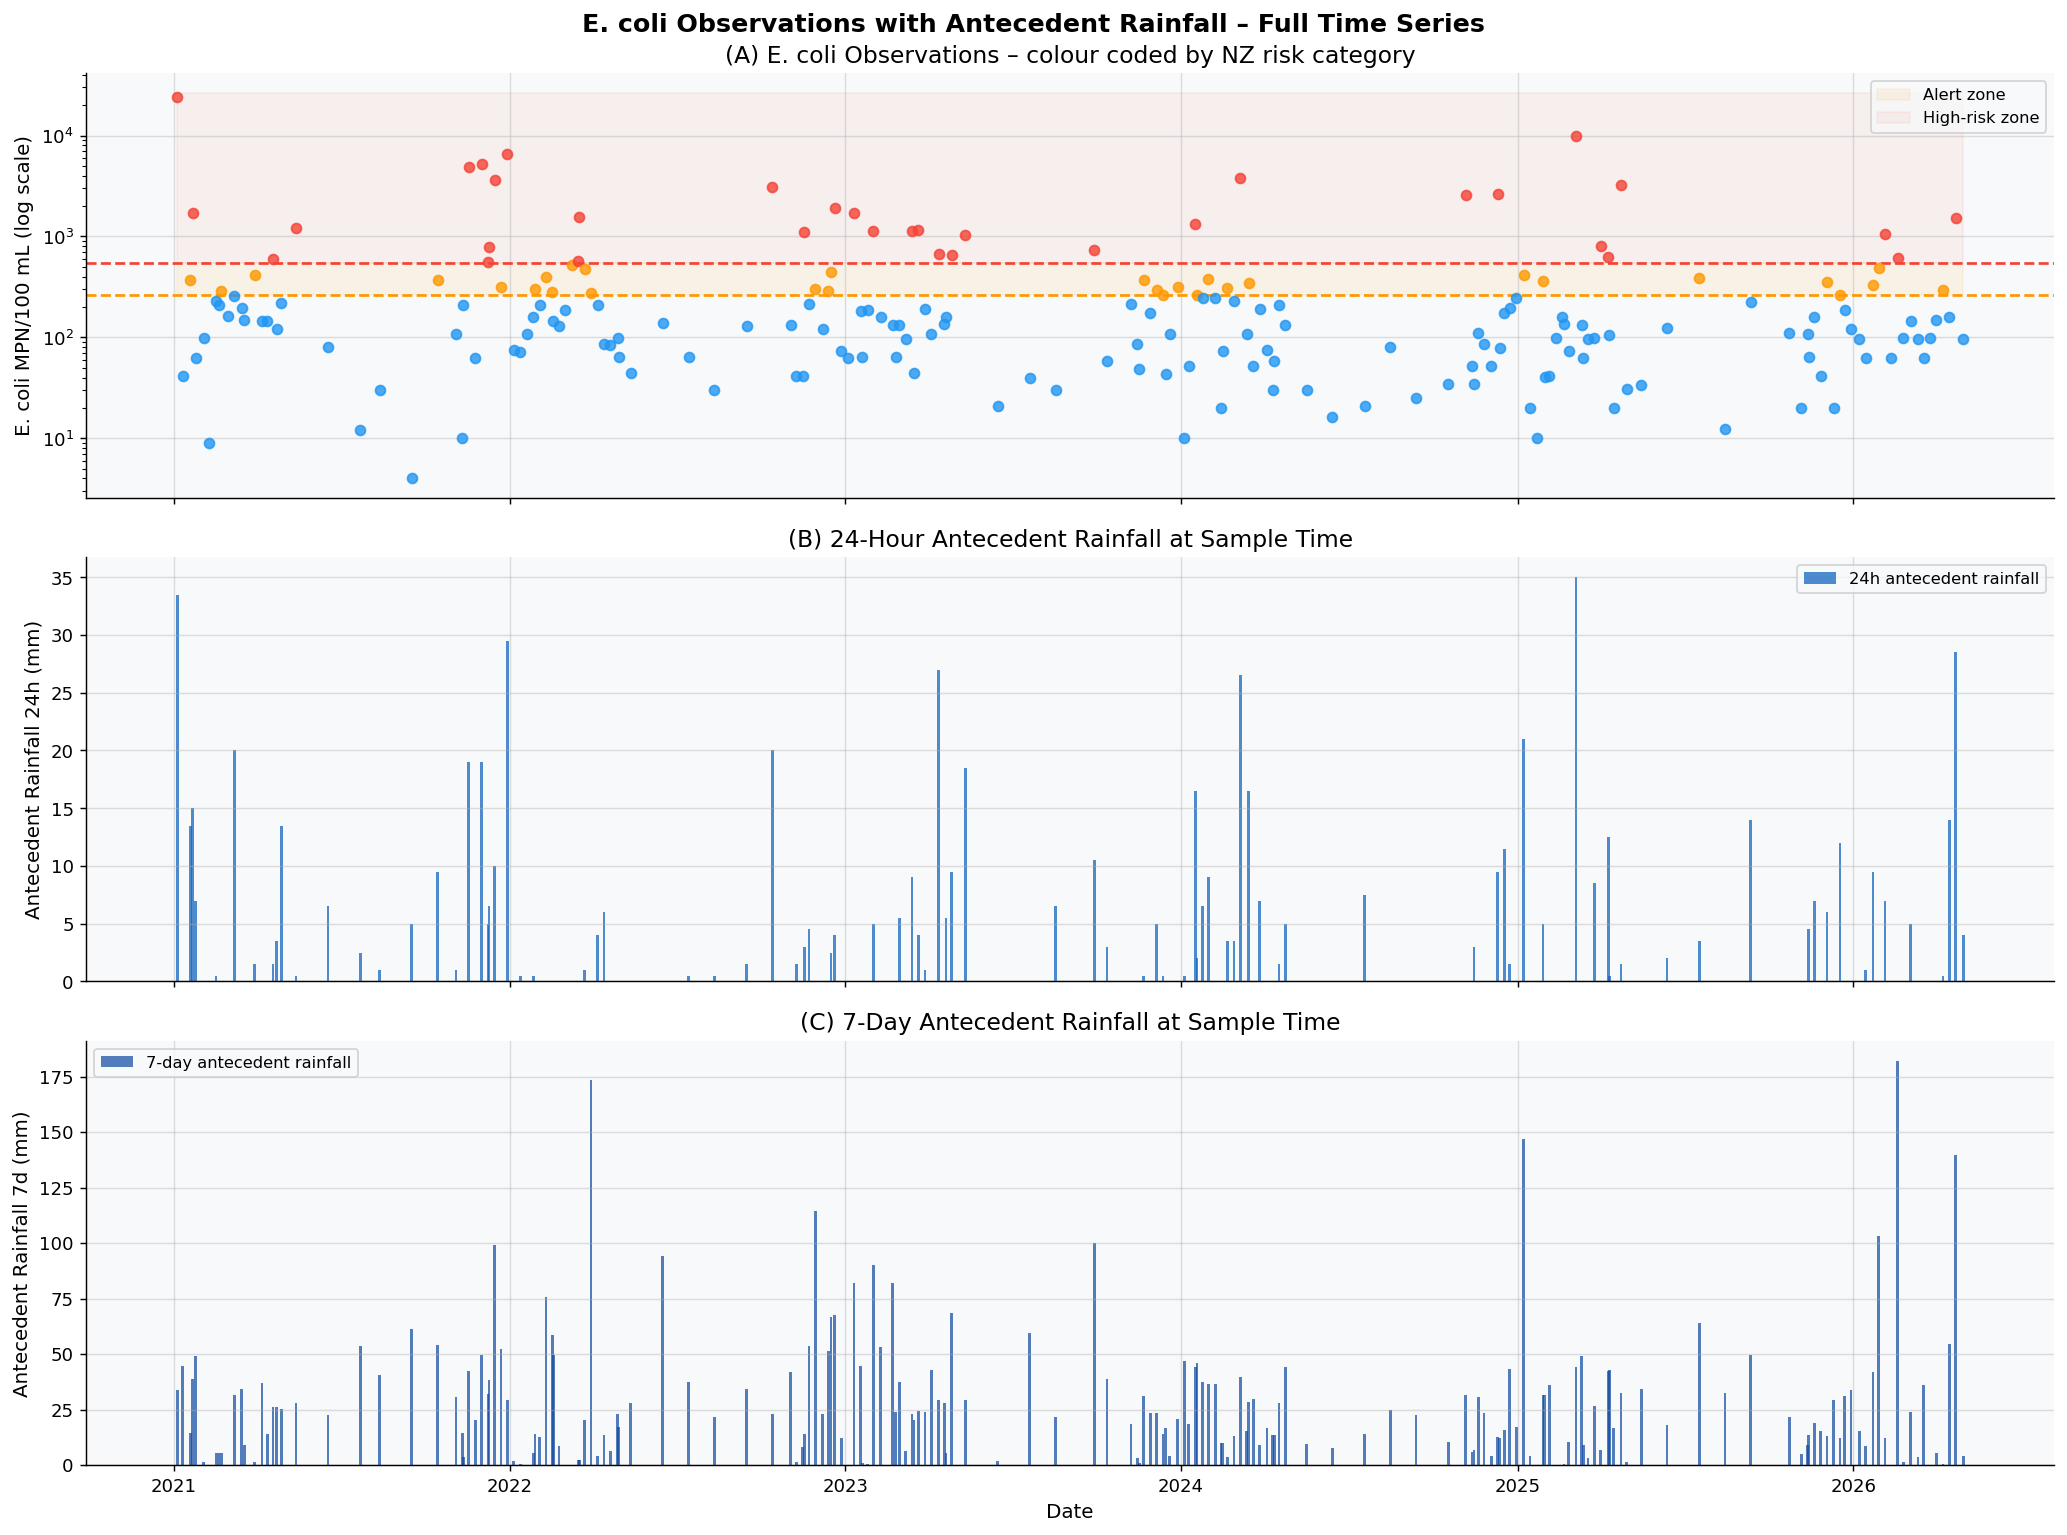

In [49]:
clr_map3 = {'Safe/Normal (<=260)': SAFE_CLR,
             'Elevated/Alert (261-540)': ALERT_CLR,
             'High-Risk (>540)': RISK_CLR}

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

ax = axes[0]
for idx, row in df.iterrows():
    ax.scatter(row['DateTime'], row['Ecoli_MPN_100mL'],
               color=clr_map3[row['Risk_Label']], s=30, alpha=0.8, zorder=4)
ax.fill_between(df['DateTime'], THRESH_ALERT, THRESH_RISK,
                alpha=0.08, color=ALERT_CLR, label='Alert zone')
ax.fill_between(df['DateTime'], THRESH_RISK, df['Ecoli_MPN_100mL'].max()*1.1,
                alpha=0.06, color=RISK_CLR, label='High-risk zone')
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_yscale('log')
ax.set_ylabel('E. coli MPN/100 mL (log scale)')
ax.set_title('(A) E. coli Observations – colour coded by NZ risk category')
ax.legend(fontsize=9, loc='upper right')

ax = axes[1]
ax.bar(df['DateTime'], df['Rain_Pre24h_mm'],
       width=3, color='#1565C0', alpha=0.75, label='24h antecedent rainfall')
ax.set_ylabel('Antecedent Rainfall 24h (mm)')
ax.set_title('(B) 24-Hour Antecedent Rainfall at Sample Time')
ax.legend(fontsize=9)

ax = axes[2]
ax.bar(df['DateTime'], df['Rain_Pre7d_mm'],
       width=3, color='#0D47A1', alpha=0.70, label='7-day antecedent rainfall')
ax.set_ylabel('Antecedent Rainfall 7d (mm)')
ax.set_xlabel('Date')
ax.set_title('(C) 7-Day Antecedent Rainfall at Sample Time')
ax.legend(fontsize=9)

plt.suptitle('E. coli Observations with Antecedent Rainfall – Full Time Series',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig09_timeseries_rainfall.png', bbox_inches='tight')
plt.show()


In [50]:
from scipy.stats import pearsonr

print("=" * 65)
print("  WATER QUALITY ANALYSIS - KEY FINDINGS SUMMARY")
print("=" * 65)

n   = len(df)
n1  = (df['Site'] == 'Oroua at Almadale').sum()
n2  = (df['Site'] == 'Oroua at Almadale Slackline').sum()
gm  = 10 ** df['Log10_Ecoli'].mean()
med = df['Ecoli_MPN_100mL'].median()

r24, _  = pearsonr(df['Rain_Pre24h_mm'], df['Log10_Ecoli'])
r48, _  = pearsonr(df['Rain_Pre48h_mm'], df['Log10_Ecoli'])
r72, _  = pearsonr(df['Rain_Pre72h_mm'], df['Log10_Ecoli'])
r7d, _  = pearsonr(df['Rain_Pre7d_mm'],  df['Log10_Ecoli'])
r12, _  = pearsonr(df['Rain_Pre12h_mm'], df['Log10_Ecoli'])
r6,  _  = pearsonr(df['Rain_Pre6h_mm'],  df['Log10_Ecoli'])

df_lag2 = df[['Rain_Lag1d_mm','Log10_Ecoli']].dropna()
r_lag1, _ = pearsonr(df_lag2['Rain_Lag1d_mm'], df_lag2['Log10_Ecoli'])

safe_n  = (df['Risk_Label'] == 'Safe/Normal (<=260)').sum()
alert_n = (df['Risk_Label'] == 'Elevated/Alert (261-540)').sum()
high_n  = (df['Risk_Label'] == 'High-Risk (>540)').sum()

lines = [
    "",
    "DATASET",
    f"  Total observations  : {n}",
    f"  Oroua at Almadale   : {n1} samples",
    f"  Almadale Slackline  : {n2} samples",
    f"  Date range          : {df['DateTime'].min().date()} to {df['DateTime'].max().date()}",
    "",
    "E. COLI SUMMARY",
    f"  Geometric mean      : {gm:.0f}  MPN/100 mL",
    f"  Median              : {med:.0f}  MPN/100 mL",
    f"  Max observed        : {df['Ecoli_MPN_100mL'].max():.0f}  MPN/100 mL",
    "",
    "NZ RISK CLASSIFICATION (MfE thresholds)",
    f"  Safe / Normal  <=260: {safe_n:>3} samples  ({safe_n/n*100:.1f}%)",
    f"  Elevated 261-540    : {alert_n:>3} samples  ({alert_n/n*100:.1f}%)",
    f"  High-Risk     >540  : {high_n:>3} samples  ({high_n/n*100:.1f}%)",
    "",
    "BEST RAINFALL PREDICTORS (Pearson r with log10 E. coli)",
    f"  24h antecedent      :  r = {r24:.3f}  *** (strongest)",
    f"  48h antecedent      :  r = {r48:.3f}  ***",
    f"  72h antecedent      :  r = {r72:.3f}  ***",
    f"  7-day antecedent    :  r = {r7d:.3f}  ***",
    f"  12h antecedent      :  r = {r12:.3f}  ***",
    f"  6h antecedent       :  r = {r6:.3f}  **",
    f"  Daily Lag-1         :  r = {r_lag1:.3f}  *",
    "",
    "IMPLICATIONS FOR MODELLING",
    "  -> 24h and 48h antecedent rainfall are the strongest",
    "     leakage-safe predictors. Prioritise in feature selection.",
    "  -> Rain_Day0_Calendar_mm is leakage-UNSAFE; exclude from models.",
    "  -> Both sites show similar E. coli-rainfall relationships;",
    "     pooling is defensible (confirm with Mann-Whitney above).",
    "  -> Use Log10_Ecoli as the regression target variable.",
    "  -> NZ MfE thresholds: 260 CFU (alert) | 540 CFU (high-risk).",
    "",
]
print("\n".join(lines))
print("=" * 65)


  WATER QUALITY ANALYSIS - KEY FINDINGS SUMMARY

DATASET
  Total observations  : 203
  Oroua at Almadale   : 144 samples
  Almadale Slackline  : 59 samples
  Date range          : 2021-01-04 to 2026-04-30

E. COLI SUMMARY
  Geometric mean      : 161  MPN/100 mL
  Median              : 144  MPN/100 mL
  Max observed        : 24200  MPN/100 mL

NZ RISK CLASSIFICATION (MfE thresholds)
  Safe / Normal  <=260: 139 samples  (68.5%)
  Elevated 261-540    :  30 samples  (14.8%)
  High-Risk     >540  :  34 samples  (16.7%)

BEST RAINFALL PREDICTORS (Pearson r with log10 E. coli)
  24h antecedent      :  r = 0.592  *** (strongest)
  48h antecedent      :  r = 0.584  ***
  72h antecedent      :  r = 0.479  ***
  7-day antecedent    :  r = 0.306  ***
  12h antecedent      :  r = 0.299  ***
  6h antecedent       :  r = 0.246  **
  Daily Lag-1         :  r = 0.211  *

IMPLICATIONS FOR MODELLING
  -> 24h and 48h antecedent rainfall are the strongest
     leakage-safe predictors. Prioritise in feature